In [23]:
# imports
import numpy as np
import matplotlib.pyplot as plt
from astropy.table import Table as table, join
from astropy.io import fits
from astropy.wcs import WCS
import matplotlib as mpl
import os
import scipy.stats
import glob
%matplotlib inline
from astropy.nddata import CCDData
import astropy.units as u
import urllib.request

In [3]:
def imdisplay(image, v1perc=10, v2perc=95):
    '''
    display an image
    OPTIONAL KEYWORD PARAMETERS
    v1perc: one end of the colormap assigned to the v1perc percent lowest flux
    v2perc: the other end of the colormap assigned to the v2perc percent highest flux
    '''
    # make sure image is an np array
    nimage = np.array(image)
    # determine the pixel values at the 10th and 95th percentile
    v1 = scoreatpercentile(nimage,v1perc)
    v2 = scoreatpercentile(nimage,v2perc)
    # display using imshow
    #
    # you can play with alternate cmaps in the function below, such as "viridis" or "gray"
    # The 'gray_r' color map reverses the color-scale so that dark display pixels are the brightest in the image
    #
    # vmin and vmax set the min and max pixel values that
    # will be mapped to the extremes of the colormap
    plt.imshow(nimage,cmap='grey_r',vmin=v1,vmax=v2)
    plt.colorbar(fraction=.08)

In [9]:
# Getting image files
base_url = "https://portal.nersc.gov/cfs/cosmo/data/legacysurvey/dr11/south/coadd"

files_M67 = {
    "M67_topleft_g": f"{base_url}/132/1328p120/legacysurvey-1328p120-image-g.fits.fz",
    "M67_topleft_r": f"{base_url}/132/1328p120/legacysurvey-1328p120-image-r.fits.fz",

    "M67_topright_g": f"{base_url}/132/1326p120/legacysurvey-1326p120-image-g.fits.fz",
    "M67_topright_r": f"{base_url}/132/1326p120/legacysurvey-1326p120-image-r.fits.fz",

    "M67_bottomleft_g": f"{base_url}/132/1329p117/legacysurvey-1329p117-image-g.fits.fz",
    "M67_bottomleft_r": f"{base_url}/132/1329p117/legacysurvey-1329p117-image-r.fits.fz",

    "M67_bottomright_g": f"{base_url}/132/1327p117/legacysurvey-1327p117-image-g.fits.fz",
    "M67_bottomright_r": f"{base_url}/132/1327p117/legacysurvey-1327p117-image-r.fits.fz",
}


files_M3 = {
    "M3_topleft_g": f"{base_url}/205/2056p285/legacysurvey-2056p285-image-g.fits.fz",
    "M3_topleft_r": f"{base_url}/205/2056p285/legacysurvey-2056p285-image-r.fits.fz",

    "M3_topright_g": f"{base_url}/205/2054p285/legacysurvey-2054p285-image-g.fits.fz",
    "M3_topright_r": f"{base_url}/205/2054p285/legacysurvey-2054p285-image-r.fits.fz",

    "M3_bottomleft_g": f"{base_url}/205/2056p282/legacysurvey-2056p282-image-g.fits.fz",
    "M3_bottomleft_r": f"{base_url}/205/2056p282/legacysurvey-2056p282-image-r.fits.fz",

    "M3_bottomright_g": f"{base_url}/205/2053p282/legacysurvey-2053p282-image-g.fits.fz",
    "M3_bottomright_r": f"{base_url}/205/2053p282/legacysurvey-2053p282-image-r.fits.fz",
}


In [7]:
# # Downloading images
# os.makedirs("fits_data", exist_ok=True)

# local_files = {}

# for name, url in files_M67.items():
#     path = f"fits_data/{name}.fits.fz"

#     if not os.path.exists(path):
#         print(f"Downloading {name}...")
#         urllib.request.urlretrieve(url, path)

#     local_files[name] = path

# for name, url in files_M3.items():
#     path = f"fits_data/{name}.fits.fz"

#     if not os.path.exists(path):
#         print(f"Downloading {name}...")
#         urllib.request.urlretrieve(url, path)

#     local_files[name] = path

# print("All files downloaded.")

All files downloaded.


In [11]:
# Get structure and header information
image_data = {}
image_headers = {}

keywords = [
    "BUNIT", "FILTER", "NAXIS1", "NAXIS2",
    "CRVAL1", "CRVAL2", "CRPIX1", "CRPIX2",
    "CD1_1", "CD1_2", "CD2_1", "CD2_2"
]

for name, path in local_files.items():
    with fits.open(path) as hdul:
        print(f"\n{'='*60}")
        print(name)
        hdul.info()

        # Find the first 2D image HDU
        image_hdu = next(
            hdu for hdu in hdul
            if hdu.data is not None and hdu.data.ndim == 2
        )

        image_data[name] = image_hdu.data
        image_headers[name] = image_hdu.header

        print("Image shape:", image_hdu.data.shape)

        for key in keywords:
            print(f"{key}: {image_hdu.header.get(key, 'Not available')}")


M67_topleft_g
Filename: fits_data/M67_topleft_g.fits.fz
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       6   ()      
  1  IMAGE_g       1 CompImageHDU    133   (3600, 3600)   float32   
Image shape: (3600, 3600)
BUNIT: nanomaggy
FILTER: g DECam SDSS c0001 4720.0 1520.0
NAXIS1: 3600
NAXIS2: 3600
CRVAL1: 132.893617021277
CRVAL2: 12.0
CRPIX1: 1800.5
CRPIX2: 1800.5
CD1_1: -7.27777777777778e-05
CD1_2: 0.0
CD2_1: 0.0
CD2_2: 7.27777777777778e-05

M67_topleft_r
Filename: fits_data/M67_topleft_r.fits.fz
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       6   ()      
  1  IMAGE_r       1 CompImageHDU    133   (3600, 3600)   float32   
Image shape: (3600, 3600)
BUNIT: nanomaggy
FILTER: r DECam SDSS c0002 6415.0 1480.0
NAXIS1: 3600
NAXIS2: 3600
CRVAL1: 132.893617021277
CRVAL2: 12.0
CRPIX1: 1800.5
CRPIX2: 1800.5
CD1_1: -7.27777777777778e-05
CD1_2: 0.0
CD2_1: 0.0
CD2_2: 7.27777777777778e-05

M67_top

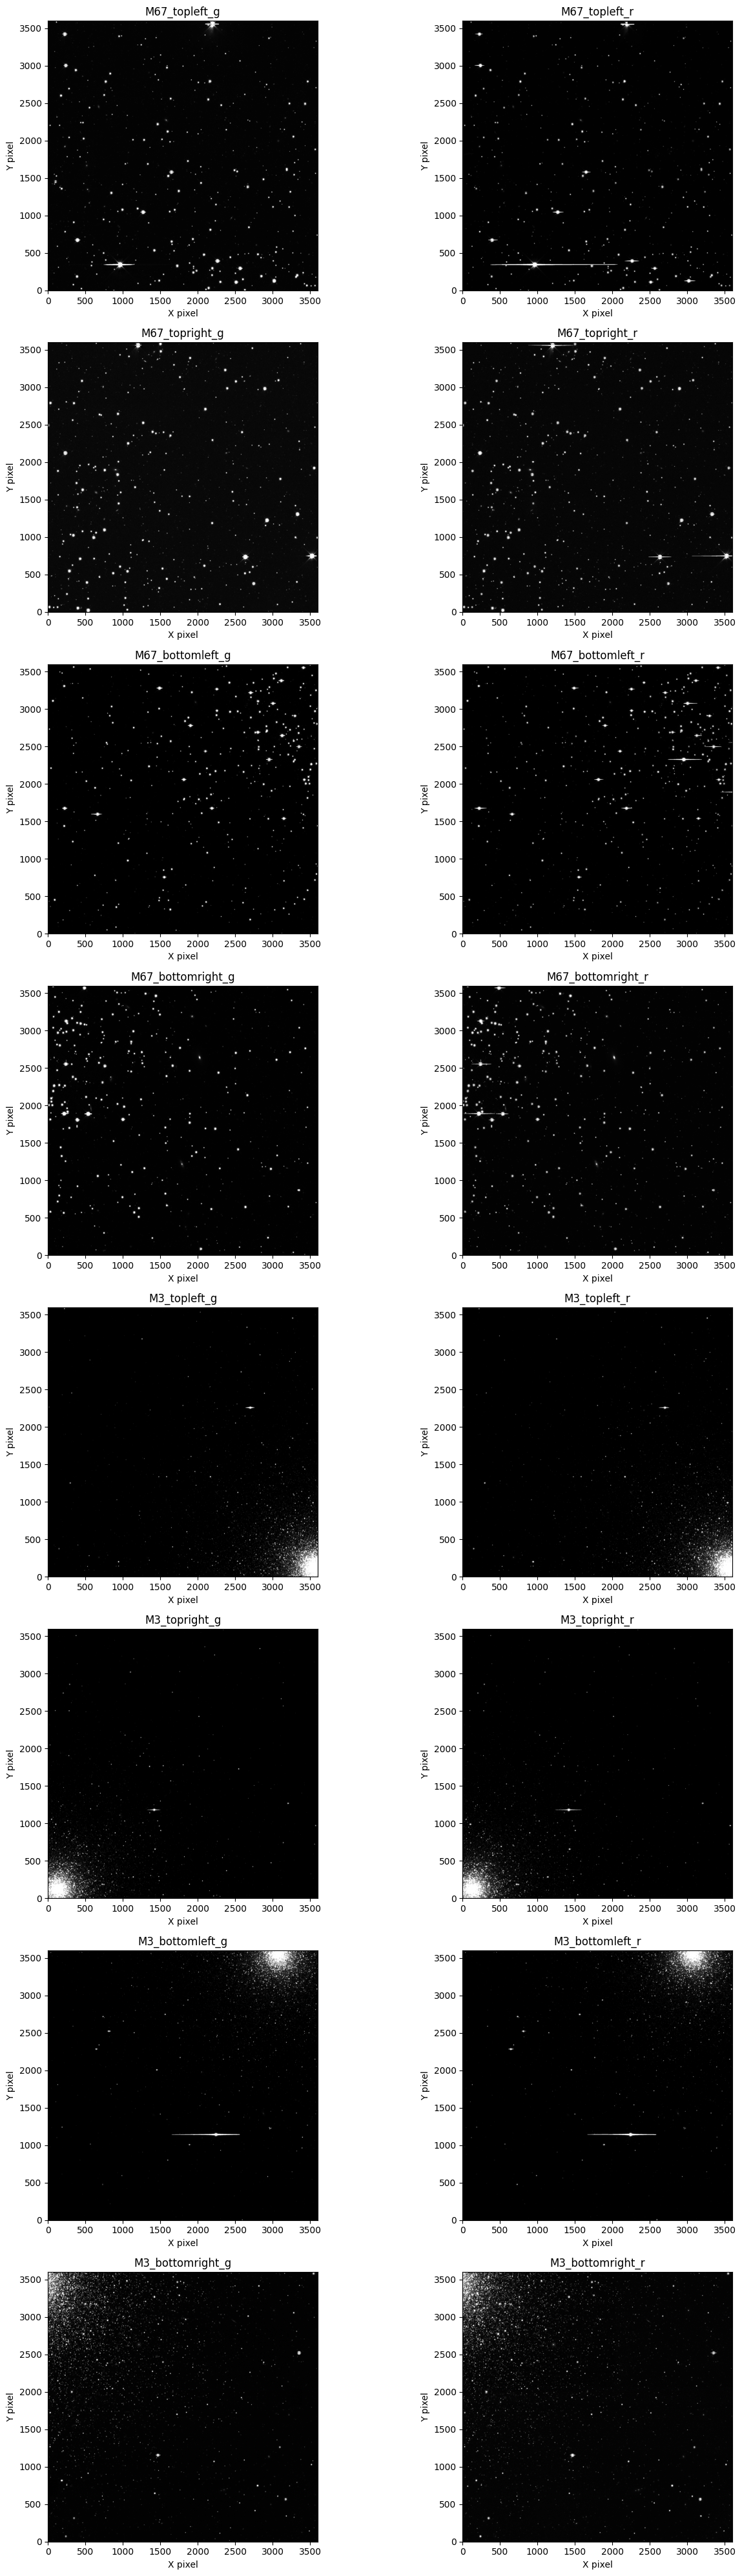

In [13]:
# Display images
fig, axes = plt.subplots(8, 2, figsize=(14, 40))

for ax, (name, data) in zip(axes.flat, image_data.items()):
    vmin = np.nanpercentile(data, 5)
    vmax = np.nanpercentile(data, 99.5)

    ax.imshow(
        data,
        origin="lower",
        cmap="gray",
        vmin=vmin,
        vmax=vmax
    )

    ax.set_title(name)
    ax.set_xlabel("X pixel")
    ax.set_ylabel("Y pixel")

plt.tight_layout()
plt.show()

In [27]:
# from photutils.detection import DAOStarFinder
# from astropy.stats import sigma_clipped_stats
# from photutils.aperture import CircularAperture
# from astropy.visualization import SqrtStretch
# from astropy.visualization.mpl_normalize import ImageNormalize
from astropy.wcs import WCS
from astropy.io import fits
import glob
import os
from scipy.stats import scoreatpercentile

from matplotlib import pyplot as plt
import numpy as np

#import ccdproc

from astropy.nddata import CCDData
import astropy.units as u
from ccdproc import ImageFileCollection, Combiner, combine
from ccdproc import wcs_project

ModuleNotFoundError: No module named 'ccdproc'

In [ ]:
m3_rimage_list = 
m3_gimage_list = 
m67_rimage_list = 
m67_gimage_list = 

In [ ]:
# We will reproject all the images to align them with the first image in each of the lists for a given filter.
#start with the R-band data
reprojected = []
#loop through each image name
for image_name in m3_rimage_list:
    #read the image into a "CCDData" object
    img = CCDData.read(image_name)
    #take each image, and reproject it onto an identical coordinate grid to the target image
    new_image = wcs_project(img, target_wcs)
    #this is a list of all the reprojected images
    reprojected.append(new_image)

# combine the reprojected images into one image
combiner = Combiner(reprojected)
rstacked_image = combiner.average_combine()


# save the combined image
fits.writeto('/Users/terrymechem/jupyter_notebooks/ASTR591_code/capstone/test.fits',rstacked_image,overwrite=True,header=rheader)
# display the combined image
plt.figure()
imdisplay(rstacked_image)
plt.title('R-band image')